
# Phase 5 - Super-Clustering Contextual v5.1 (Walk-Forward K Optimization)

Objetivo: mejorar resultados OOS manteniendo el mejor encoder contextual ya entrenado (v2),
optimizando solo la selección de `K` con validación temporal walk-forward en `train+val`.

Principios:
- No se usa `test` para seleccionar `K`.
- Se evalúa robustez por múltiples folds temporales y múltiples seeds de KMeans.
- Se re-entrena KMeans final en `train+val` y se perfila en `test`.


Loading: ./phases/phase05_context_sequencing/output_superclustering_contextual_GBPUSD_v2/GBPUSD_context_window_embeddings.parquet
n windows = 1605 | dim = 64
split counts: {'train': 1123, 'val': 241, 'test': 241}
folds: [(682, 136), (818, 136), (954, 137), (1091, 136)]


BEST_K = 7


,k,folds_used,eta2_wf_mean,eta2_wf_median,kw_wf_mean,sil_wf_mean,ch_wf_mean,db_wf_mean,ari_wf_mean,z_eta,z_sil,z_ch,z_db,z_ari,wf_score
0,7,4,0.021545,0.017571,0.346745,0.111561,29.720582,1.351639,0.987256,1.409773,-0.139525,-0.418158,-0.534940,0.930490,2.161050
1,10,4,0.022905,0.015272,0.508491,0.066671,27.124018,1.408877,0.950524,1.720224,-1.060158,-1.008744,0.356547,0.204422,1.787258
2,4,4,0.015186,0.015985,0.504023,0.208556,40.170928,1.395876,0.991561,-0.041915,1.849717,1.958765,0.154065,1.015593,1.145075
3,9,4,0.017497,0.013016,0.375922,0.066853,26.835500,1.434479,0.942991,0.485698,-1.056436,-1.074367,0.755305,0.055512,-0.082372
4,6,4,0.014822,0.013855,0.427665,0.132521,31.239962,1.347583,0.902056,-0.124981,0.290339,-0.072576,-0.598107,-0.753626,-0.089069
5,8,4,0.013549,0.011786,0.508905,0.089689,28.026460,1.231073,0.971401,-0.415430,-0.588105,-0.803484,-2.412752,0.617089,-0.221530
6,12,4,0.013167,0.011018,0.518720,0.111408,33.607044,1.426872,0.867148,-0.502741,-0.142662,0.465815,0.636830,-1.443650,-1.108543
7,5,4,0.008539,0.009346,0.662071,0.193634,37.454485,1.427795,0.994353,-1.559179,1.543684,1.340912,0.651196,1.070772,-1.323023
8,11,4,0.011114,0.010497,0.564368,0.084386,29.852457,1.449667,0.854351,-0.971449,-0.696856,-0.388163,0.991855,-1.696602,-2.268845


saved summary: ./phases/phase05_context_sequencing/output_superclustering_contextual_GBPUSD_v5_kwalk/GBPUSD_superclustering_summary_v5_1.json
test metrics -> kw_p: 0.0034255361753562585 | anova_p: 0.0018398858847684472 | eta2: 0.07616097285151815


,regime_id,n,mean_ret,median_ret,std_ret,t_like
0,5,72,-20.013932,-21.299720,96.484035,-0.207433
1,6,55,19.850926,20.799637,85.643181,0.231786
2,2,47,-48.140414,-58.000088,163.736717,-0.294011
3,1,25,59.555912,52.499771,133.056588,0.447598
4,3,21,1.190617,-2.000332,106.842334,0.011144
5,4,11,-30.000101,0.000000,76.766745,-0.390796
6,0,10,-13.669968,-35.799742,80.721167,-0.169348


,model,best_k,kw_pvalue_test,anova_pvalue_test,eta2_test
0,v2,6,0.004396,0.004857,0.063914
1,v4_transfer,4,0.156393,0.070865,0.022853
2,v5_improved,10,0.023002,0.012388,0.060452
3,v5_1_kwalk,7,0.003426,0.001840,0.076161


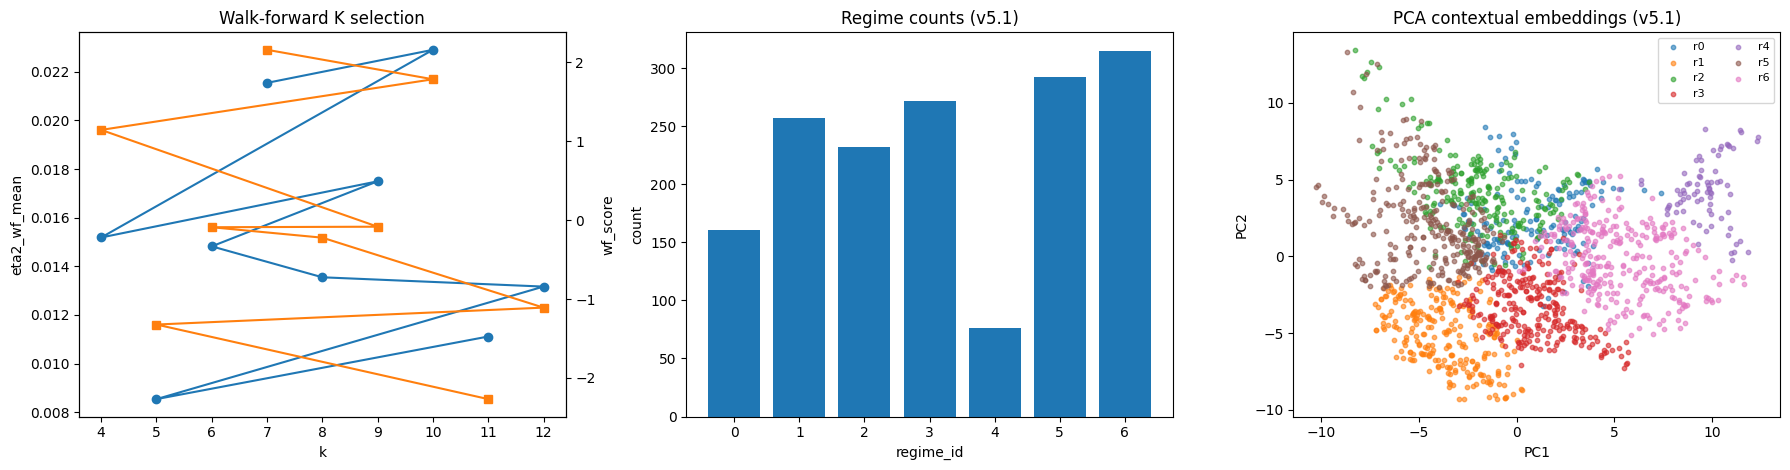

In [1]:

import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score, adjusted_rand_score
from scipy.stats import kruskal, f_oneway

pd.set_option('display.max_columns', 220)
pd.set_option('display.width', 320)

# =========================
# Config
# =========================
SYMBOL = 'GBPUSD'
SEED = 42
K_CANDIDATES = list(range(4, 13))
KMEANS_SEEDS = [11, 42, 77]
N_INIT_KMEANS = 50
HORIZON_HOURS = 24
MIN_CLUSTER_N_FOLD = 15
MIN_CLUSTER_N_TEST = 20

# walk-forward folds sobre train+val (expanding)
FOLD_SPECS = [
    (0.50, 0.10),
    (0.60, 0.10),
    (0.70, 0.10),
    (0.80, 0.10),
]

ROOT = Path('./phases/phase05_context_sequencing')
IN_PQ = ROOT / 'output_superclustering_contextual_GBPUSD_v2/GBPUSD_context_window_embeddings.parquet'
OUT_DIR = ROOT / 'output_superclustering_contextual_GBPUSD_v5_kwalk'
OUT_DIR.mkdir(parents=True, exist_ok=True)

MODEL_SEL_CSV = OUT_DIR / 'GBPUSD_k_selection_walkforward_v5_1.csv'
EMB_PQ = OUT_DIR / 'GBPUSD_context_window_embeddings_v5_1.parquet'
EMB_CSV = OUT_DIR / 'GBPUSD_context_window_embeddings_v5_1.csv'
PROFILE_CSV = OUT_DIR / 'GBPUSD_context_regime_profile_v5_1.csv'
TRANS_CSV = OUT_DIR / 'GBPUSD_context_regime_transition_matrix_v5_1.csv'
SUMMARY_JSON = OUT_DIR / 'GBPUSD_superclustering_summary_v5_1.json'

V2_SUM = ROOT / 'output_superclustering_contextual_GBPUSD_v2/GBPUSD_superclustering_summary.json'
V4_SUM = ROOT / 'output_superclustering_contextual_GBPUSD_v4_transfer/GBPUSD_superclustering_summary_v4.json'
V5_SUM = ROOT / 'output_superclustering_contextual_GBPUSD_v5_improved/GBPUSD_superclustering_summary_v5.json'

print('Loading:', IN_PQ)
DF = pd.read_parquet(IN_PQ).copy()
emb_cols = [c for c in DF.columns if c.startswith('ctx_emb_')]
Z = DF[emb_cols].to_numpy(dtype=float)
ret = pd.to_numeric(DF['ret_fwd_24h_pips'], errors='coerce').to_numpy(dtype=float)

idx_tr = np.where(DF['split'].to_numpy() == 'train')[0]
idx_va = np.where(DF['split'].to_numpy() == 'val')[0]
idx_te = np.where(DF['split'].to_numpy() == 'test')[0]
idx_tv = np.concatenate([idx_tr, idx_va])

print('n windows =', len(DF), '| dim =', Z.shape[1])
print('split counts:', DF['split'].value_counts().to_dict())

# =========================
# Build walk-forward folds
# =========================
n_tv = len(idx_tv)
folds = []
for tr_r, va_r in FOLD_SPECS:
    tr_end = int(n_tv * tr_r)
    va_end = min(n_tv, int(n_tv * (tr_r + va_r)))
    if va_end - tr_end < 30:
        continue
    folds.append((idx_tv[:tr_end], idx_tv[tr_end:va_end]))

print('folds:', [(len(a), len(b)) for a, b in folds])

# =========================
# K selection
# =========================
rows = []
for k in K_CANDIDATES:
    fold_eta2 = []
    fold_kw = []
    fold_sil = []
    fold_ch = []
    fold_db = []
    fold_ari = []

    for tr_idx, va_idx in folds:
        sc = StandardScaler()
        Ztr = sc.fit_transform(Z[tr_idx])
        Zva = sc.transform(Z[va_idx])

        seed_labels = {}
        sils, chs, dbs = [], [], []
        for sd in KMEANS_SEEDS:
            km = KMeans(n_clusters=k, n_init=N_INIT_KMEANS, random_state=sd)
            km.fit(Ztr)
            lv = km.predict(Zva)
            seed_labels[sd] = lv
            if len(np.unique(lv)) >= 2 and len(lv) > k:
                sils.append(float(silhouette_score(Zva, lv)))
                chs.append(float(calinski_harabasz_score(Zva, lv)))
                dbs.append(float(davies_bouldin_score(Zva, lv)))

        # stability between seeds
        aris = []
        keys = list(seed_labels.keys())
        for i in range(len(keys)):
            for j in range(i + 1, len(keys)):
                aris.append(float(adjusted_rand_score(seed_labels[keys[i]], seed_labels[keys[j]])))

        lv = seed_labels[42]
        rv = ret[va_idx]
        ok = np.isfinite(rv)
        rv = rv[ok]
        lv = lv[ok]

        groups = []
        for cid in np.unique(lv):
            g = rv[lv == cid]
            if len(g) >= MIN_CLUSTER_N_FOLD:
                groups.append(g)

        if len(groups) >= 2:
            kw = float(kruskal(*groups).pvalue)
            all_vals = np.concatenate(groups)
            gm = np.mean(all_vals)
            ssb = sum(len(g) * (np.mean(g) - gm) ** 2 for g in groups)
            sst = np.sum((all_vals - gm) ** 2)
            eta2 = float(ssb / sst) if sst > 0 else np.nan
            fold_kw.append(kw)
            fold_eta2.append(eta2)

        if sils:
            fold_sil.append(float(np.mean(sils)))
        if chs:
            fold_ch.append(float(np.mean(chs)))
        if dbs:
            fold_db.append(float(np.mean(dbs)))
        if aris:
            fold_ari.append(float(np.mean(aris)))

    row = {
        'k': int(k),
        'folds_used': int(len(fold_eta2)),
        'eta2_wf_mean': float(np.nanmean(fold_eta2)) if fold_eta2 else np.nan,
        'eta2_wf_median': float(np.nanmedian(fold_eta2)) if fold_eta2 else np.nan,
        'kw_wf_mean': float(np.nanmean(fold_kw)) if fold_kw else np.nan,
        'sil_wf_mean': float(np.nanmean(fold_sil)) if fold_sil else np.nan,
        'ch_wf_mean': float(np.nanmean(fold_ch)) if fold_ch else np.nan,
        'db_wf_mean': float(np.nanmean(fold_db)) if fold_db else np.nan,
        'ari_wf_mean': float(np.nanmean(fold_ari)) if fold_ari else np.nan,
    }
    rows.append(row)

SEL = pd.DataFrame(rows)

def zcol(s):
    s = pd.to_numeric(s, errors='coerce')
    m = float(s.mean())
    sd = float(s.std(ddof=0))
    if not np.isfinite(sd) or sd < 1e-9:
        return pd.Series(np.zeros(len(s)), index=s.index, dtype=float)
    return (s - m) / (sd + 1e-9)

SEL['z_eta'] = zcol(SEL['eta2_wf_mean'])
SEL['z_sil'] = zcol(SEL['sil_wf_mean'])
SEL['z_ch'] = zcol(SEL['ch_wf_mean'])
SEL['z_db'] = zcol(SEL['db_wf_mean'])
SEL['z_ari'] = zcol(SEL['ari_wf_mean'])

# score principal: eta2 walk-forward, con regularizacion geométrica/estabilidad
SEL['wf_score'] = 1.40*SEL['z_eta'] + 0.35*SEL['z_sil'] + 0.20*SEL['z_ch'] - 0.25*SEL['z_db'] + 0.20*SEL['z_ari']
SEL = SEL.sort_values('wf_score', ascending=False).reset_index(drop=True)
BEST_K = int(SEL.iloc[0]['k'])
SEL.to_csv(MODEL_SEL_CSV, index=False)

print('BEST_K =', BEST_K)
display(SEL)

# =========================
# Final clustering train+val -> all
# =========================
sc = StandardScaler()
Z_tv = sc.fit_transform(Z[idx_tv])
Z_all = sc.transform(Z)

KM = KMeans(n_clusters=BEST_K, n_init=N_INIT_KMEANS, random_state=SEED)
KM.fit(Z_tv)
reg = KM.predict(Z_all)
dist = KM.transform(Z_all).min(axis=1)

OUT = DF[['window_id', 'symbol', 'start_ts', 'end_ts', 'split']].copy()
OUT['regime_id'] = reg.astype(int)
OUT['regime_dist'] = dist.astype(float)
OUT['regime_token'] = OUT['regime_id'].map(lambda x: f'r{x:02d}')
OUT['ret_fwd_24h_pips'] = ret

for c in emb_cols:
    OUT[c] = DF[c].to_numpy()

# profile test
test_df = OUT[OUT['split'] == 'test'].copy()
prof = (test_df.groupby('regime_id')['ret_fwd_24h_pips']
        .agg(n='count', mean_ret='mean', median_ret='median', std_ret='std')
        .reset_index())
prof['t_like'] = prof['mean_ret'] / prof['std_ret'].replace(0, np.nan)
prof = prof.sort_values('n', ascending=False).reset_index(drop=True)

groups = []
for rid, g in test_df.groupby('regime_id'):
    x = g['ret_fwd_24h_pips'].dropna().to_numpy()
    if len(x) >= MIN_CLUSTER_N_TEST:
        groups.append(x)

kw_p = np.nan
anova_p = np.nan
eta2 = np.nan
if len(groups) >= 2:
    kw_p = float(kruskal(*groups).pvalue)
    anova_p = float(f_oneway(*groups).pvalue)
    all_vals = np.concatenate(groups)
    gm = np.mean(all_vals)
    ssb = sum(len(g) * (np.mean(g) - gm) ** 2 for g in groups)
    sst = np.sum((all_vals - gm) ** 2)
    eta2 = float(ssb / sst) if sst > 0 else np.nan

# transition matrix
tr = pd.crosstab(OUT['regime_token'], OUT['regime_token'].shift(-1)).fillna(0)
tr_prob = tr.div(tr.sum(axis=1), axis=0).fillna(0.0)

OUT.to_parquet(EMB_PQ, index=False)
OUT.to_csv(EMB_CSV, index=False)
prof.to_csv(PROFILE_CSV, index=False)
tr_prob.to_csv(TRANS_CSV)

summary = {
    'symbol': SYMBOL,
    'model_tag': 'v5_1_kwalk_on_v2_encoder',
    'base_encoder': 'v2_contextual_transformer',
    'n_windows': int(len(OUT)),
    'split_counts': {k: int(v) for k, v in OUT['split'].value_counts().to_dict().items()},
    'best_k': int(BEST_K),
    'kw_pvalue_test': None if not np.isfinite(kw_p) else float(kw_p),
    'anova_pvalue_test': None if not np.isfinite(anova_p) else float(anova_p),
    'eta2_test': None if not np.isfinite(eta2) else float(eta2),
    'wf_score_best_k': float(SEL.iloc[0]['wf_score']),
    'eta2_wf_mean_best_k': None if not np.isfinite(SEL.iloc[0]['eta2_wf_mean']) else float(SEL.iloc[0]['eta2_wf_mean']),
}
SUMMARY_JSON.write_text(json.dumps(summary, indent=2))

print('saved summary:', SUMMARY_JSON)
print('test metrics -> kw_p:', kw_p, '| anova_p:', anova_p, '| eta2:', eta2)
display(prof)

# =========================
# Compare summaries
# =========================
def read_json(p):
    return json.loads(p.read_text()) if p.exists() else {}

v2 = read_json(V2_SUM)
v4 = read_json(V4_SUM)
v5 = read_json(V5_SUM)
v51 = read_json(SUMMARY_JSON)

CMP = pd.DataFrame([
    {'model': 'v2', 'best_k': v2.get('best_k'), 'kw_pvalue_test': v2.get('kw_pvalue_test'), 'anova_pvalue_test': v2.get('anova_pvalue_test'), 'eta2_test': v2.get('eta2_test')},
    {'model': 'v4_transfer', 'best_k': v4.get('best_k'), 'kw_pvalue_test': v4.get('kw_pvalue_test'), 'anova_pvalue_test': v4.get('anova_pvalue_test'), 'eta2_test': v4.get('eta2_test')},
    {'model': 'v5_improved', 'best_k': v5.get('best_k'), 'kw_pvalue_test': v5.get('kw_pvalue_test'), 'anova_pvalue_test': v5.get('anova_pvalue_test'), 'eta2_test': v5.get('eta2_test')},
    {'model': 'v5_1_kwalk', 'best_k': v51.get('best_k'), 'kw_pvalue_test': v51.get('kw_pvalue_test'), 'anova_pvalue_test': v51.get('anova_pvalue_test'), 'eta2_test': v51.get('eta2_test')},
])
display(CMP)

# =========================
# Plot diagnostics
# =========================
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))

axes[0].plot(SEL['k'], SEL['eta2_wf_mean'], marker='o', label='eta2_wf_mean')
ax2 = axes[0].twinx()
ax2.plot(SEL['k'], SEL['wf_score'], marker='s', color='tab:orange', label='wf_score')
axes[0].set_title('Walk-forward K selection')
axes[0].set_xlabel('k')
axes[0].set_ylabel('eta2_wf_mean')
ax2.set_ylabel('wf_score')

cnt = OUT['regime_id'].value_counts().sort_index()
axes[1].bar(cnt.index.astype(str), cnt.values)
axes[1].set_title('Regime counts (v5.1)')
axes[1].set_xlabel('regime_id')
axes[1].set_ylabel('count')

# PCA view
from sklearn.decomposition import PCA
xy = PCA(n_components=2, random_state=SEED).fit_transform(Z_all)
for rid in sorted(np.unique(OUT['regime_id'])):
    m = OUT['regime_id'].to_numpy() == rid
    axes[2].scatter(xy[m, 0], xy[m, 1], s=10, alpha=0.6, label=f'r{rid}')
axes[2].set_title('PCA contextual embeddings (v5.1)')
axes[2].set_xlabel('PC1')
axes[2].set_ylabel('PC2')
axes[2].legend(ncol=2, fontsize=8)

plt.tight_layout()
plt.show()
